# 03 · Session length suggestion (k-nearest neighbours)

**In the app:** **Log session** pre-fills the duration and marks the closest quick chip as *Suggested*.

**Data, stated honestly:** a real public dataset with *timed* study sessions (start hour + length) would be ideal. The
American Time Use Survey has one, but the US Bureau of Labor Statistics blocks scripted downloads, and OULAD only logs
daily click counts with no times or durations. This notebook therefore **tunes** the k-NN hyper-parameters on a transparent
simulator (`milestone_sim.py`). The model itself has no trained weights. **On the phone it predicts purely from the user's own
logged sessions**, so the simulator only influences 5 hyper-parameters, never the predictions' content.

Distance between a new session *q* and a past session *p*:

$d = w_s[\text{subject differs}] + w_h\frac{|h_q-h_p|}{12} + w_d[\text{weekday differs}] + w_a\frac{\text{age}_{days}}{30}$

Prediction = inverse-distance-weighted **mean or median** of the *k* nearest past durations, rounded to 5 minutes.
(Note: the baseline MAEs below are computed without rounding, whereas the app rounds its suggestion to 5 minutes and
only looks at the latest 400 sessions.)
Session lengths are right-skewed and we score with absolute error, which a median minimises, so both are tried. A simple
per-subject median is also included as a baseline, and if it wins, the app ships that behaviour instead.

In [1]:
import json, pathlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = pathlib.Path('data')
PROC = DATA / 'processed'
ASSETS = pathlib.Path('../app/src/main/assets/ml')
ASSETS.mkdir(parents=True, exist_ok=True)
RED, INK, GREY, LINE = '#E11D2A', '#111111', '#8C8C8C', '#DEDEDE'

def is_test(student_id):
    """Deterministic 20% hold-out split by student (no student appears in both sets)."""
    return int(hashlib.md5(str(student_id).encode()).hexdigest(), 16) % 5 == 0

In [2]:
from milestone_sim import SimConfig, simulate
subjects, sessions = simulate(SimConfig())
s = sessions.sort_values(['user', 'date', 'hour']).reset_index(drop=True)
s['wd'] = s.date.dt.weekday
s['day'] = (s.date - s.date.min()).dt.days
s['sid'] = s.groupby('user').subject.transform(lambda x: pd.factorize(x)[0])
print(f'{s.user.nunique()} simulated users, {len(s):,} sessions')

def wmedian(values, weights):
    o = np.argsort(values); c = np.cumsum(weights[o])
    return values[o][np.searchsorted(c, c[-1] / 2)]

def evaluate(users, k, ws, wh, wd, wa, min_hist=3, eps=0.05):
    err, err_med, b_user, b_subj, b_subj_med, b_last = [], [], [], [], [], []
    for u in users:
        g = s[s.user == u]
        sid, hr, wkd, day = (g[c].to_numpy() for c in ['sid', 'hour', 'wd', 'day'])
        dur = g.duration_min.to_numpy(float)
        for i in range(min_hist, len(g)):
            d = (ws * (sid[:i] != sid[i]) + wh * np.abs(hr[:i] - hr[i]) / 12 +
                 wd * (wkd[:i] != wkd[i]) + wa * (day[i] - day[:i]) / 30)
            o = np.argsort(d)[:k]; wt = 1 / (d[o] + eps)
            err.append(abs(np.round((wt * dur[:i][o]).sum() / wt.sum() / 5) * 5 - dur[i]))
            err_med.append(abs(np.round(wmedian(dur[:i][o], wt) / 5) * 5 - dur[i]))
            b_user.append(abs(dur[:i].mean() - dur[i]))
            same = dur[:i][sid[:i] == sid[i]]
            b_subj.append(abs((same.mean() if len(same) else dur[:i].mean()) - dur[i]))
            b_subj_med.append(abs((np.median(same) if len(same) else np.median(dur[:i])) - dur[i]))
            b_last.append(abs((same[-1] if len(same) else dur[i-1]) - dur[i]))
    return dict(knn_mean=np.mean(err), knn_median=np.mean(err_med), subject_median=np.mean(b_subj_med),
                subject_mean=np.mean(b_subj), user_mean=np.mean(b_user), last_same_subject=np.mean(b_last))

users = s.user.unique()
tune, test_users = users[users % 5 != 0][:80], users[users % 5 == 0]

300 simulated users, 140,036 sessions


In [3]:
grid = [(k, ws, wh, wd, wa) for k in [3, 5, 8, 12] for ws in [1, 3] for wh in [0.5, 1.5]
        for wd in [0, 0.3] for wa in [0.1, 0.5]]
grid = [g + (agg,) for g in grid for agg in ['knn_mean', 'knn_median']]
cache = {}
def score(g):
    key = g[:5]
    if key not in cache: cache[key] = evaluate(tune, *key)
    return cache[key][g[5]]
scores = {g: score(g) for g in grid}
BEST = min(scores, key=scores.get)
print('best (k, w_subject, w_hour, w_weekday, w_age, aggregate) =', BEST, f'| tuning MAE {scores[BEST]:.2f} min')
pd.Series(scores).sort_values().head(6).round(2)

best (k, w_subject, w_hour, w_weekday, w_age, aggregate) = (12, 1, 0.5, 0, 0.1, 'knn_mean') | tuning MAE 19.40 min


12  1  0.5  0.0  0.1  knn_mean    19.40
    3  0.5  0.0  0.1  knn_mean    19.42
       1.5  0.0  0.1  knn_mean    19.46
    1  1.5  0.0  0.1  knn_mean    19.47
    3  1.5  0.3  0.5  knn_mean    19.48
                 0.1  knn_mean    19.51
dtype: float64

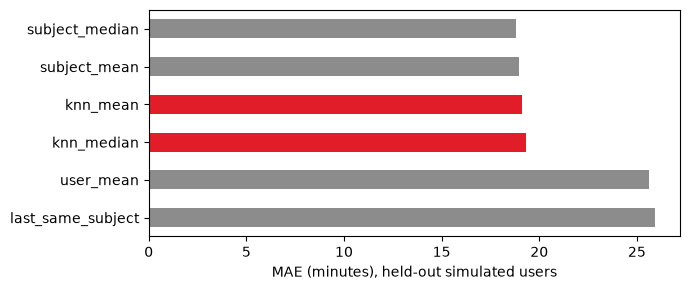

subject_median       18.81
subject_mean         18.97
knn_mean             19.13
knn_median           19.33
user_mean            25.64
last_same_subject    25.91
dtype: float64

In [4]:
res = pd.Series(evaluate(test_users, *BEST[:5])).sort_values()
ax = res.iloc[::-1].plot(kind='barh', color=[RED if k.startswith('knn') else GREY for k in res.index[::-1]], figsize=(7, 3))
ax.set_xlabel('MAE (minutes), held-out simulated users'); plt.tight_layout(); plt.show()
res.round(2)

In [5]:
k, ws, wh, wd, wa, agg = BEST
winner = res.index[0]
print(f'held-out winner: {winner} ({res.iloc[0]:.2f} min). k-NN {agg}: {res[agg]:.2f} min, '
      f'subject median: {res["subject_median"]:.2f} min')
# Honesty rule: if a simple baseline wins on held-out users, ship the baseline's behaviour instead.
# k-NN with a huge subject weight, no other terms and a very large k *is* the subject median: same-subject
# sessions get weight 1/eps = 20, other subjects ~1e-6, and with no same-subject history it falls back to the
# median of all sessions, exactly like the baseline. So the app needs no second code path.
if winner == 'subject_median':
    k, ws, wh, wd, wa, agg = 1000, 1e6, 0.0, 0.0, 0.0, 'knn_median'
export = {
    'version': 2, 'source': 'hyper-parameters tuned on simulated logs (see notebook); predictions use only on-device user data',
    'k': int(k), 'w_subject': float(ws), 'w_hour': float(wh), 'w_weekday': float(wd), 'w_age': float(wa),
    'aggregate': 'median' if agg == 'knn_median' else 'mean',
    'epsilon': 0.05, 'min_history': 3, 'max_history': 400, 'fallback_minutes': 45,
    'sim_test_mae_minutes': {k_: float(v) for k_, v in res.items()},
}
(ASSETS / 'duration_knn.json').write_text(json.dumps(export, indent=2))
export

held-out winner: subject_median (18.81 min). k-NN knn_mean: 19.13 min, subject median: 18.81 min


{'version': 2,
 'source': 'hyper-parameters tuned on simulated logs (see notebook); predictions use only on-device user data',
 'k': 1000,
 'w_subject': 1000000.0,
 'w_hour': 0.0,
 'w_weekday': 0.0,
 'w_age': 0.0,
 'aggregate': 'median',
 'epsilon': 0.05,
 'min_history': 3,
 'max_history': 400,
 'fallback_minutes': 45,
 'sim_test_mae_minutes': {'subject_median': 18.80753806295915,
  'subject_mean': 18.97486800649349,
  'knn_mean': 19.132980799943216,
  'knn_median': 19.33349895304681,
  'user_mean': 25.637934006372245,
  'last_same_subject': 25.91138162330979}}